# Análisis de Probabilidad y Estadística II: actividad física

**Equipo:** Miranda Meléndez García, Valeria Vázquez Salazar, Jael Alejandro Sustayt Godínez y Jorge Alejandro Huerta Reyes  
**Institución:** Universidad de Guadalajara  
**Periodo:** 2026A

Este notebook desarrolla el análisis descriptivo y las tres pruebas de hipótesis incluidas en el reporte. Las pruebas inferenciales se programan manualmente: no se utilizan `scipy.stats`, `statsmodels` ni funciones de pruebas estadísticas.

**Archivo de entrada:** `datos_limpios.csv`. Coloca el CSV en la misma carpeta que este notebook o selecciona su ruta en la celda de carga.

## 1. Librerías y configuración

Se utilizan `pandas` y `numpy` para manipulación de datos y operaciones numéricas, y `matplotlib` para las gráficas. Estas librerías no ejecutan las pruebas inferenciales por nosotros.

In [1]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

print("Entorno listo.")
print("Python:", __import__("sys").version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Entorno listo.
Python: 3.14.8
Pandas: 3.0.6
NumPy: 2.5.3


## 2. Carga de datos

El archivo contiene las columnas `Date`, `Duration`, `Pulse`, `Maxpulse` y `Calories`. Si el CSV no está en el directorio de trabajo, modifica `RUTA_CSV` con la ubicación correcta.

In [2]:
RUTA_CSV = "datos_limpios.csv"  
if not os.path.exists(RUTA_CSV):
    raise FileNotFoundError(
        f"No se encontró {RUTA_CSV}. Coloca el CSV junto al notebook o actualiza RUTA_CSV."
    )

df = pd.read_csv(RUTA_CSV)
print("Dimensiones:", df.shape)
display(df.head())
display(df.info())

Dimensiones: (100, 5)


,Date,Duration,Pulse,Maxpulse,Calories
0,2023-01-01,90.0,117,156,409.6
1,2023-01-02,120.0,96,117,837.8
2,2023-01-03,60.0,98,123,362.2
3,2023/01/04,60.0,97,138,583.7
4,2023-01-05,120.0,101,131,394.7


<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      100 non-null    str    
 1   Duration  100 non-null    float64
 2   Pulse     100 non-null    int64  
 3   Maxpulse  100 non-null    int64  
 4   Calories  100 non-null    float64
dtypes: float64(2), int64(2), str(1)
memory usage: 4.0 KB


None

## 3. Exploración y calidad de los datos

Se revisan tipos de datos, valores faltantes, registros duplicados y medidas generales. En el archivo recibido hay 100 registros y no se detectan valores faltantes en las cinco columnas. La fuente original y el protocolo de medición no están documentados dentro del CSV.

In [3]:
print("Tipos de datos:")
display(df.dtypes.to_frame("tipo"))

print("\\nValores faltantes:")
display(df.isna().sum().to_frame("faltantes"))

print("\\nFilas duplicadas:", df.duplicated().sum())
print("\\nResumen de variables numéricas:")
display(df.describe().T)

columnas_requeridas = {"Date", "Duration", "Pulse", "Maxpulse", "Calories"}
faltantes_columnas = columnas_requeridas - set(df.columns)
if faltantes_columnas:
    raise ValueError(f"Faltan columnas requeridas: {faltantes_columnas}")

variables = ["Duration", "Pulse", "Maxpulse", "Calories"]
for col in variables:
    df[col] = pd.to_numeric(df[col], errors="coerce")

if df[variables].isna().any().any():
    raise ValueError("Hay valores no numéricos o faltantes en variables de análisis; revisar el CSV.")

print("\\nComprobación final: registros =", len(df),
      "| faltantes numéricos =", int(df[variables].isna().sum().sum()))

Tipos de datos:


,tipo
Date,str
Duration,float64
Pulse,int64
Maxpulse,int64
Calories,float64


\nValores faltantes:


,faltantes
Date,0
Duration,0
Pulse,0
Maxpulse,0
Calories,0


\nFilas duplicadas: 0
\nResumen de variables numéricas:


,count,mean,std,min,25%,50%,75%,max
Duration,100.0,87.900,129.8779,30.0,45.0,60.0,90.00,1200.0
Pulse,100.0,110.360,12.5469,90.0,98.0,113.0,121.00,129.0
Maxpulse,100.0,144.510,15.6686,114.0,132.0,146.0,155.25,175.0
Calories,100.0,467.162,210.4042,165.5,318.2,409.6,590.15,986.2


\nComprobación final: registros = 100 | faltantes numéricos = 0


## 4. Estadística descriptiva

La media y la desviación estándar describen centro y dispersión. También se reportan mediana y cuartiles porque la duración presenta valores extremos (300, 600 y 1200 minutos), que pueden elevar la media.

In [4]:
resumen = df[variables].agg(["count", "mean", "std", "min", "median", "max"]).T
resumen["Q1"] = df[variables].quantile(0.25)
resumen["Q3"] = df[variables].quantile(0.75)
display(resumen)

print("Frecuencia por duración:")
display(df["Duration"].value_counts().sort_index().rename_axis("Duración (min)").to_frame("n"))

,count,mean,std,min,median,max,Q1,Q3
Duration,100.0,87.900,129.8779,30.0,60.0,1200.0,45.0,90.00
Pulse,100.0,110.360,12.5469,90.0,113.0,129.0,98.0,121.00
Maxpulse,100.0,144.510,15.6686,114.0,146.0,175.0,132.0,155.25
Calories,100.0,467.162,210.4042,165.5,409.6,986.2,318.2,590.15


Frecuencia por duración:


,n
Duración (min),
30.0,17
45.0,20
60.0,20
90.0,24
120.0,16
300.0,1
600.0,1
1200.0,1


## 5. Visualización de los datos

Las siguientes gráficas permiten observar distribuciones, diferencias entre mediciones y la relación entre duración y calorías.

<Figure size 800x500 with 0 Axes>

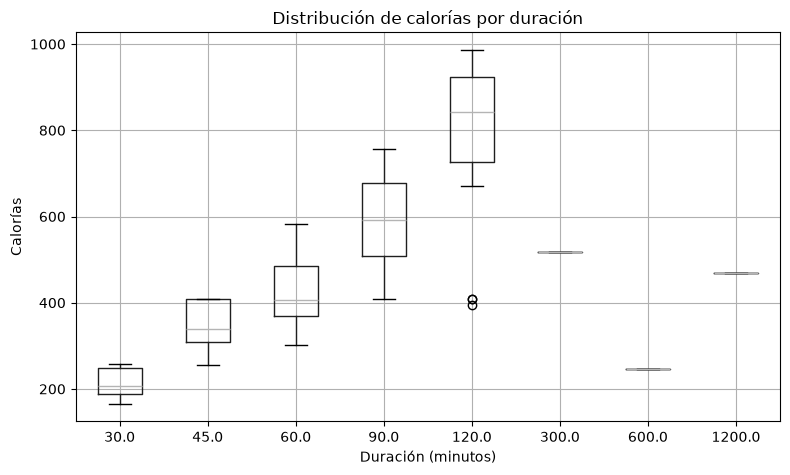

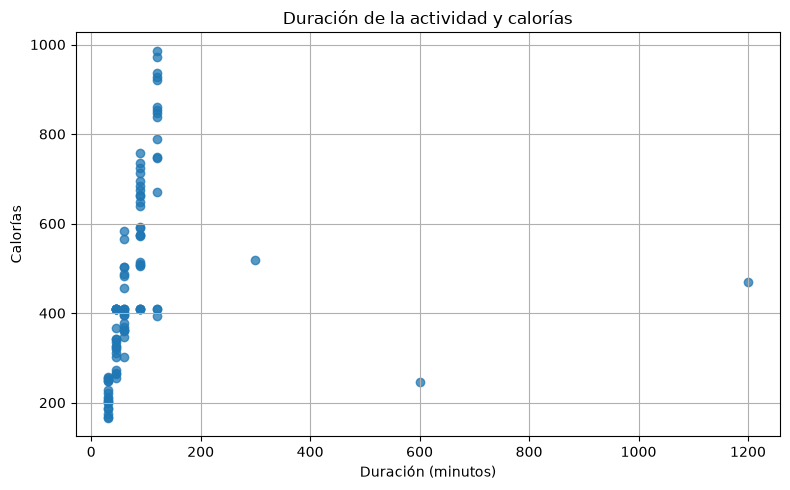

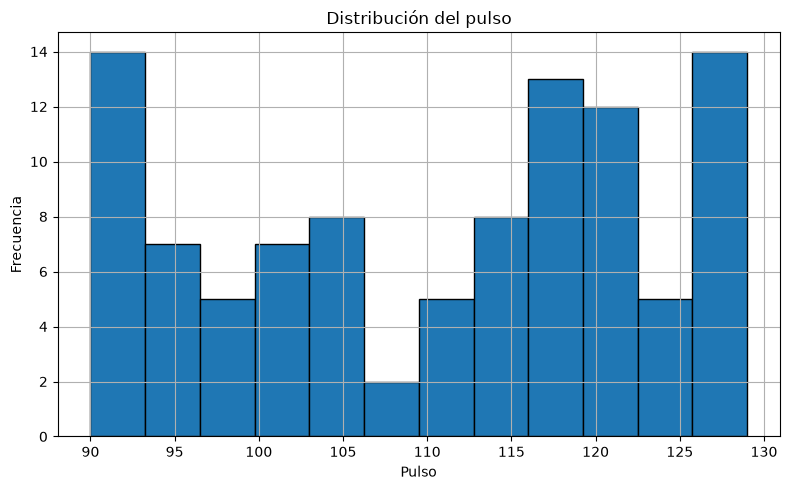

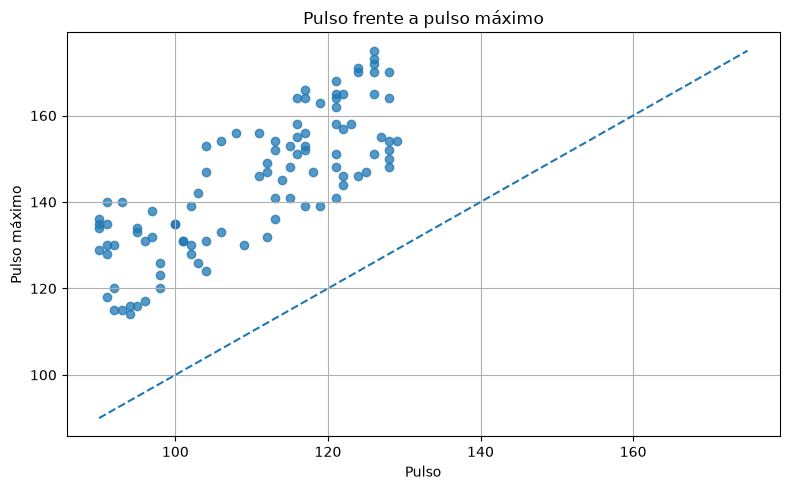

In [5]:
plt.figure()
df.boxplot(column="Calories", by="Duration", grid=True)
plt.title("Distribución de calorías por duración")
plt.suptitle("")
plt.xlabel("Duración (minutos)")
plt.ylabel("Calorías")
plt.tight_layout()
plt.savefig("grafica_calorias_duracion.png", dpi=180, bbox_inches="tight")
plt.show()

plt.figure()
plt.scatter(df["Duration"], df["Calories"], alpha=0.75)
plt.title("Duración de la actividad y calorías")
plt.xlabel("Duración (minutos)")
plt.ylabel("Calorías")
plt.tight_layout()
plt.savefig("grafica_duracion_calorias.png", dpi=180, bbox_inches="tight")
plt.show()

plt.figure()
plt.hist(df["Pulse"], bins=12, edgecolor="black")
plt.title("Distribución del pulso")
plt.xlabel("Pulso")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.savefig("grafica_distribucion_pulso.png", dpi=180, bbox_inches="tight")
plt.show()

plt.figure()
plt.scatter(df["Pulse"], df["Maxpulse"], alpha=0.75)
lim_inf = min(df["Pulse"].min(), df["Maxpulse"].min())
lim_sup = max(df["Pulse"].max(), df["Maxpulse"].max())
plt.plot([lim_inf, lim_sup], [lim_inf, lim_sup], linestyle="--")
plt.title("Pulso frente a pulso máximo")
plt.xlabel("Pulso")
plt.ylabel("Pulso máximo")
plt.tight_layout()
plt.savefig("grafica_pulso_pulso_maximo.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Funciones matemáticas para calcular valores p

Las siguientes funciones implementan la función beta incompleta regularizada mediante fracciones continuas y, a partir de ella, las colas de las distribuciones t y F. Se programan explícitamente para evitar utilizar bibliotecas de inferencia estadística.

In [6]:
def beta_continued_fraction(a, b, x, max_iter=300, eps=3e-14, fpmin=1e-300):
    qab = a + b
    qap = a + 1.0
    qam = a - 1.0
    c = 1.0
    d = 1.0 - qab * x / qap
    if abs(d) < fpmin:
        d = fpmin
    d = 1.0 / d
    h = d

    for m in range(1, max_iter + 1):
        m2 = 2 * m
        aa = m * (b - m) * x / ((qam + m2) * (a + m2))
        d = 1.0 + aa * d
        if abs(d) < fpmin: d = fpmin
        c = 1.0 + aa / c
        if abs(c) < fpmin: c = fpmin
        d = 1.0 / d
        h *= d * c

        aa = -(a + m) * (qab + m) * x / ((a + m2) * (qap + m2))
        d = 1.0 + aa * d
        if abs(d) < fpmin: d = fpmin
        c = 1.0 + aa / c
        if abs(c) < fpmin: c = fpmin
        d = 1.0 / d
        delta = d * c
        h *= delta
        if abs(delta - 1.0) < eps:
            break
    return h


def beta_regularizada(x, a, b):
    if not (a > 0 and b > 0):
        raise ValueError("a y b deben ser positivos.")
    if x <= 0: return 0.0
    if x >= 1: return 1.0
    bt = math.exp(
        math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b)
        + a * math.log(x) + b * math.log1p(-x)
    )
    if x < (a + 1.0) / (a + b + 2.0):
        return bt * beta_continued_fraction(a, b, x) / a
    return 1.0 - bt * beta_continued_fraction(b, a, 1.0 - x) / b


def cola_t_bilateral(t_obs, gl):
    x = gl / (gl + t_obs**2)
    return beta_regularizada(x, gl / 2.0, 0.5)


def cola_f_derecha(F_obs, gl1, gl2):
    x = gl2 / (gl2 + gl1 * F_obs)
    return beta_regularizada(x, gl2 / 2.0, gl1 / 2.0)

print("Funciones de distribución implementadas.")

Funciones de distribución implementadas.


## 7. Prueba 1: t de Student para observaciones pareadas

**Pregunta:** ¿El pulso máximo promedio difiere del pulso promedio medido en las mismas sesiones?

- **H₀:** En la población de sesiones representada, el pulso máximo y el pulso registrado no presentan una diferencia promedio.
- **H₁:** En esa población, el pulso máximo y el pulso registrado sí presentan una diferencia promedio distinta de cero.

Se calcula la diferencia individual `Maxpulse - Pulse`. Se usa una prueba bilateral con α = 0.05. Se supone que los pares corresponden a la misma sesión, que las diferencias entre sesiones son independientes y que la distribución de diferencias es aproximadamente normal (o que la aproximación por tamaño muestral es razonable).

In [7]:
diferencias = (df["Maxpulse"] - df["Pulse"]).to_numpy(dtype=float)
n_p = len(diferencias)
media_d = diferencias.mean()
sd_d = diferencias.std(ddof=1)
se_d = sd_d / math.sqrt(n_p)
t_pareada = media_d / se_d
gl_pareada = n_p - 1
p_pareada = cola_t_bilateral(abs(t_pareada), gl_pareada)
dz = media_d / sd_d

def t_critico_bilateral(alpha, gl):
    objetivo = alpha
    bajo, alto = 0.0, 20.0
    for _ in range(100):
        medio = (bajo + alto) / 2
        if cola_t_bilateral(medio, gl) > objetivo:
            bajo = medio
        else:
            alto = medio
    return (bajo + alto) / 2

tcrit = t_critico_bilateral(0.05, gl_pareada)
ic_inf = media_d - tcrit * se_d
ic_sup = media_d + tcrit * se_d

print(f"n = {n_p}")
print(f"Diferencia media (Maxpulse - Pulse) = {media_d:.4f}")
print(f"Desviación estándar de diferencias = {sd_d:.4f}")
print(f"t({gl_pareada}) = {t_pareada:.4f}")
print(f"Valor p bilateral = {p_pareada:.8g}")
print(f"IC 95% de la diferencia media = [{ic_inf:.4f}, {ic_sup:.4f}]")
print(f"d de Cohen para pares (dz) = {dz:.4f}")

if p_pareada < 0.05:
    print("Decisión: se rechaza H0. Hay evidencia de una diferencia promedio.")
else:
    print("Decisión: no se rechaza H0. La evidencia no es suficiente para afirmar una diferencia promedio.")

n = 100
Diferencia media (Maxpulse - Pulse) = 34.1500
Desviación estándar de diferencias = 9.3294
t(99) = 36.6047
Valor p bilateral = 2.3965189e-59
IC 95% de la diferencia media = [32.2988, 36.0012]
d de Cohen para pares (dz) = 3.6605
Decisión: se rechaza H0. Hay evidencia de una diferencia promedio.


## 8. Prueba 2: ANOVA de un factor

**Pregunta:** ¿Las calorías medias son iguales entre sesiones de 30, 45, 60, 90 y 120 minutos?

- **H₀:** Las medias poblacionales de calorías de los cinco grupos de duración son iguales.
- **H₁:** Al menos una de las cinco medias poblacionales es diferente.

Los registros de 300, 600 y 1200 minutos se mantienen en el análisis descriptivo, pero no se incluyen en ANOVA porque cada uno tiene una sola observación y no permite estimar la variabilidad intragrupo. Se comparan 97 observaciones en cinco grupos. Supuestos: independencia, residuos aproximadamente normales y varianzas similares.

In [8]:
duraciones_anova = [30, 45, 60, 90, 120]
df_anova = df[df["Duration"].isin(duraciones_anova)].copy()
grupos = [g["Calories"].to_numpy(dtype=float) for _, g in df_anova.groupby("Duration", sort=True)]

k = len(grupos)
N = sum(len(g) for g in grupos)
media_general = np.concatenate(grupos).mean()

SC_entre = sum(len(g) * (g.mean() - media_general)**2 for g in grupos)
SC_dentro = sum(((g - g.mean())**2).sum() for g in grupos)
SC_total = SC_entre + SC_dentro

gl_entre = k - 1
gl_dentro = N - k
CM_entre = SC_entre / gl_entre
CM_dentro = SC_dentro / gl_dentro
F_obs = CM_entre / CM_dentro
p_anova = cola_f_derecha(F_obs, gl_entre, gl_dentro)
eta2 = SC_entre / SC_total

tabla_grupos = df_anova.groupby("Duration")["Calories"].agg(["count", "mean", "std"])
display(tabla_grupos)

print(f"N = {N}; k = {k}")
print(f"SC entre = {SC_entre:.4f}")
print(f"SC dentro = {SC_dentro:.4f}")
print(f"F({gl_entre}, {gl_dentro}) = {F_obs:.4f}")
print(f"Valor p = {p_anova:.8g}")
print(f"Eta cuadrada = {eta2:.4f}")

if p_anova < 0.05:
    print("Decisión: se rechaza H0. Al menos una media de calorías difiere.")
else:
    print("Decisión: no se rechaza H0. No hay evidencia suficiente de diferencias entre medias.")

,count,mean,std
Duration,,,
30.0,17,212.8824,31.4481
45.0,20,344.5300,56.3960
60.0,20,424.3700,74.7524
90.0,24,590.6667,111.1095
120.0,16,769.4062,200.0905


N = 97; k = 5
SC entre = 3263996.9682
SC dentro = 1066909.1314
F(4, 92) = 70.3639
Valor p = 3.6603056e-27
Eta cuadrada = 0.7537
Decisión: se rechaza H0. Al menos una media de calorías difiere.


## 9. Prueba 3: significancia de la correlación de Pearson

**Pregunta:** ¿Existe una asociación lineal entre duración y calorías?

- **H₀:** En la población de la que proceden los registros no existe asociación lineal entre duración y calorías (ρ = 0).
- **H₁:** En esa población sí existe una asociación lineal distinta de cero (ρ ≠ 0).

Se utiliza una prueba bilateral. Pearson mide asociación lineal, no causalidad, y puede verse afectado por valores extremos.

In [9]:
x = df["Duration"].to_numpy(dtype=float)
y = df["Calories"].to_numpy(dtype=float)
n_corr = len(x)
r = np.sum((x-x.mean())*(y-y.mean())) / math.sqrt(
    np.sum((x-x.mean())**2) * np.sum((y-y.mean())**2)
)
t_corr = r * math.sqrt((n_corr - 2) / (1 - r**2))
gl_corr = n_corr - 2
p_corr = cola_t_bilateral(abs(t_corr), gl_corr)

print(f"n = {n_corr}")
print(f"r de Pearson = {r:.6f}")
print(f"t({gl_corr}) = {t_corr:.4f}")
print(f"Valor p bilateral = {p_corr:.6f}")

if p_corr < 0.05:
    print("Decisión: se rechaza H0. Hay evidencia de asociación lineal.")
else:
    print("Decisión: no se rechaza H0. No hay evidencia suficiente de asociación lineal al 5%.")

n = 100
r de Pearson = 0.162757
t(98) = 1.6330
Valor p bilateral = 0.105680
Decisión: no se rechaza H0. No hay evidencia suficiente de asociación lineal al 5%.


## 10. Comparación e interpretación conjunta

Las tres pruebas responden preguntas diferentes:

1. La prueba pareada analiza diferencias dentro de cada sesión entre dos mediciones relacionadas.
2. ANOVA compara medias de calorías entre cinco categorías de duración; un resultado significativo no identifica por sí solo qué pares de grupos difieren.
3. Pearson evalúa la fuerza y dirección de una asociación lineal entre dos variables numéricas.

No es contradictorio que ANOVA resulte significativo y Pearson no: ANOVA compara medias entre categorías, mientras Pearson evalúa una tendencia lineal a nivel de observaciones individuales. Los valores extremos de duración también pueden influir en la correlación.

In [10]:
tabla_resultados = pd.DataFrame({
    "Prueba": ["t pareada", "ANOVA", "Pearson"],
    "Estadístico": [f"t = {t_pareada:.4f}", f"F = {F_obs:.4f}", f"t = {t_corr:.4f}"],
    "Grados de libertad": [str(gl_pareada), f"{gl_entre}, {gl_dentro}", str(gl_corr)],
    "Valor p": [p_pareada, p_anova, p_corr],
    "Decisión (α=0.05)": [
        "Rechazar H0" if p_pareada < 0.05 else "No rechazar H0",
        "Rechazar H0" if p_anova < 0.05 else "No rechazar H0",
        "Rechazar H0" if p_corr < 0.05 else "No rechazar H0"
    ]
})
display(tabla_resultados)

,Prueba,Estadístico,Grados de libertad,Valor p,Decisión (α=0.05)
0,t pareada,t = 36.6047,99,2.3965e-59,Rechazar H0
1,ANOVA,F = 70.3639,"4, 92",3.6603e-27,Rechazar H0
2,Pearson,t = 1.6330,98,1.0568e-01,No rechazar H0


## 11. Errores tipo I y tipo II

**Error tipo I:** rechazar una hipótesis nula que en realidad es verdadera. En este trabajo significaría concluir que existe una diferencia de pulso, diferencias entre medias de calorías o correlación lineal cuando esas diferencias/asociación no existen en la población. Con α = 0.05, cada prueba tiene un nivel nominal de 5% de error tipo I bajo sus supuestos; al realizar varias pruebas, el riesgo conjunto puede ser mayor.

**Error tipo II:** no rechazar una hipótesis nula falsa. Podría ocurrir si no se detectara una diferencia o asociación que sí existe. Su probabilidad es β y la potencia estadística es 1 − β. La potencia depende del tamaño de muestra, variabilidad, magnitud del efecto y nivel de significancia.

Un valor p mayor que 0.05 no demuestra que la hipótesis nula sea verdadera; indica que los datos no proporcionan evidencia suficiente para rechazarla al nivel establecido.

## 12. Limitaciones y conclusiones

- El CSV no documenta su fuente original, selección de participantes, unidades detalladas ni protocolo de medición.
- Los tres registros de 300, 600 y 1200 minutos tienen una observación cada uno; por ello no se incluyeron en el ANOVA.
- No se ejecutaron pruebas formales de normalidad ni homogeneidad de varianzas. En particular, las desviaciones estándar de calorías difieren entre grupos, por lo que el supuesto de varianzas iguales debe revisarse.
- No se aplicaron comparaciones post hoc para identificar qué grupos específicos difieren.
- Correlación no implica causalidad.

**Conclusión:** con α = 0.05, la prueba pareada encontró evidencia de una diferencia media entre pulso máximo y pulso; ANOVA encontró evidencia de diferencias entre las medias de calorías de los cinco grupos analizados; la prueba de Pearson no encontró evidencia suficiente de una asociación lineal entre duración y calorías. Estas conclusiones se limitan a la información y calidad de la base disponible.

## 13. Referencias de consulta

Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2nd ed.). Lawrence Erlbaum Associates.

Heckert, N. A., Filliben, J. J., Croarkin, C. M., Hembree, B., Guthrie, W. F., Tobias, P., & Prinz, J. (2002). *NIST/SEMATECH e-Handbook of Statistical Methods*. National Institute of Standards and Technology. https://www.itl.nist.gov/div898/handbook/

Illowsky, B., & Dean, S. (2023). *Introductory statistics 2e*. OpenStax. https://openstax.org/details/books/introductory-statistics-2e

Montgomery, D. C., & Runger, G. C. (2018). *Applied statistics and probability for engineers* (7th ed.). Wiley.

Equipo de trabajo. (2026). *datos_limpios.csv* [Conjunto de datos proporcionado para el análisis; fuente primaria no indicada en el archivo].